# Employee Attrition Prediction

## 1. Problem Introduction

**Employee attrition** is when employees leave an organization, whether by resigning, being let go, or retiring. It matters because replacing someone costs money (recruiting, training) and time (the new person takes a while to become productive), and a team that loses people frequently can struggle to keep its knowledge and momentum.

This project uses a public HR dataset to look at three questions:

1. **Understanding the problem:** What is attrition, why does it matter, and what can data tell us about it?
2. **Analyzing the data:** Which employee characteristics are associated with leaving?
3. **Building a predictive model:** Can we predict which employees are more likely to leave, how reliable are the predictions, and where does the model fall short?

**Prediction task.** Binary classification. For each employee, predict `Attrition` (Yes = left, No = stayed) from the other columns.

A model like this could help an HR team decide where to look more closely, for example which groups might need a conversation or a policy review. It does not solve retention by itself. It cannot tell us *why* someone leaves, and acting on individual predictions raises fairness and privacy concerns that are discussed at the end.

**Correlation, prediction and causation.** Throughout the notebook, "associated with" means the pattern shows up in the data. A feature can help a model predict attrition without causing attrition (for example, it may just be a stand-in for something else). Nothing here establishes cause and effect.

## 2. Imports and Configuration

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42

# Works whether Jupyter is started from the project root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "raw" / "employee_attrition.csv"
CHARTS_DIR = ROOT / "charts"
CHARTS_DIR.mkdir(exist_ok=True)

# Chart styling: two colours for the two outcomes, neutral grey for the baseline
C_STAYED, C_LEFT = "#2a78d6", "#eb6834"
C_BASELINE, C_LR, C_RF = "#9a9892", "#2a78d6", "#6250d6"
INK = "#3b3a37"

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": "#c9c8c3",
    "xtick.color": INK, "ytick.color": INK, "grid.color": "#e6e5e1",
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "savefig.dpi": 150, "savefig.bbox": "tight",
})

## 3. Load and Inspect the Dataset

### Where the data comes from

| | |
|---|---|
| **Dataset** | IBM HR Analytics Employee Attrition & Performance |
| **What it is** | A *fictional* dataset created by IBM data scientists (the IEEE DataPort listing describes it that way). It is not real employee data from a real company. |
| **File used** | `data/raw/employee_attrition.csv`, downloaded from IBM's own GitHub repository: <https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv> |
| **Best-known public page** | Kaggle: <https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset> (I could not open Kaggle from my working environment, so the file came from the IBM repository instead) |
| **Licence / usage** | The IBM repository's page lists the *code* under Apache 2.0 and the dataset under the Open Database License (ODbL) with the Database Contents License (DbCL). Secondary sources describe the dataset's terms as loosely specified but free for educational use. Check the repository page yourself before reusing the data beyond this portfolio. |
| **Target** | `Attrition` (Yes / No) |

The file is kept untouched in `data/raw/`. All cleaning below happens on a copy in memory.

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print(f"Rows: {df_raw.shape[0]:,}   Columns: {df_raw.shape[1]}")
print()
print("Column types:")
print(df_raw.dtypes.astype(str).value_counts().to_string())

Rows: 1,470   Columns: 35

Column types:
int64    26
str       9


In [3]:
df_raw.head(3).T

,0,1,2
Age,41,49,37
Attrition,Yes,No,Yes
BusinessTravel,Travel_Rarely,Travel_Frequently,Travel_Rarely
DailyRate,1102,279,1373
Department,Sales,Research & Development,Research & Development
DistanceFromHome,1,8,2
Education,2,1,2
EducationField,Life Sciences,Life Sciences,Other
EmployeeCount,1,1,1
EmployeeNumber,1,2,4


In [4]:
print("Missing values (total):", int(df_raw.isna().sum().sum()))
print("Duplicate rows:        ", int(df_raw.duplicated().sum()))
print()
target_counts = df_raw["Attrition"].value_counts()
print(pd.DataFrame({"employees": target_counts, "share": (target_counts / len(df_raw)).round(3)}))

Missing values (total): 0
Duplicate rows:         0

           employees  share
Attrition                  
No              1233  0.839
Yes              237  0.161


In [5]:
df_raw.describe().T[["mean", "std", "min", "50%", "max"]].round(1)

,mean,std,min,50%,max
Age,36.9,9.1,18.0,36.0,60.0
DailyRate,802.5,403.5,102.0,802.0,1499.0
DistanceFromHome,9.2,8.1,1.0,7.0,29.0
Education,2.9,1.0,1.0,3.0,5.0
EmployeeCount,1.0,0.0,1.0,1.0,1.0
EmployeeNumber,1024.9,602.0,1.0,1020.5,2068.0
EnvironmentSatisfaction,2.7,1.1,1.0,3.0,4.0
HourlyRate,65.9,20.3,30.0,66.0,100.0
JobInvolvement,2.7,0.7,1.0,3.0,4.0
JobLevel,2.1,1.1,1.0,2.0,5.0


**What the inspection shows**

- 1,470 employees and 35 columns, with no missing values and no duplicate rows. The data is already tidy, so cleaning will be short.
- Attrition is **imbalanced**: 237 employees left (16.1%) and 1,233 stayed (83.9%). This matters for modeling, because a model can look accurate while rarely catching a leaver.
- Several columns are numbers that are really *codes* for ordered categories (for example `JobSatisfaction` runs 1 to 4). Others, like `EmployeeCount` and `StandardHours`, show a min equal to the max in the summary table, which hints at constant columns. The next section checks that properly.

## 4. Data Cleaning and Preparation

Before changing anything, check for constant columns, identifier columns, and values that do not make sense.

In [6]:
unique_counts = df_raw.nunique()
constant_cols = unique_counts[unique_counts == 1].index.tolist()
print("Constant columns:", constant_cols)
print("Values in each constant column:", {c: df_raw[c].iloc[0] for c in constant_cols})
print()
print("EmployeeNumber is unique for every row:", df_raw["EmployeeNumber"].is_unique)
print()
# Logical consistency checks on the tenure columns
print("YearsAtCompany > TotalWorkingYears:    ", int((df_raw["YearsAtCompany"] > df_raw["TotalWorkingYears"]).sum()))
print("YearsInCurrentRole > YearsAtCompany:   ", int((df_raw["YearsInCurrentRole"] > df_raw["YearsAtCompany"]).sum()))
print("YearsWithCurrManager > YearsAtCompany: ", int((df_raw["YearsWithCurrManager"] > df_raw["YearsAtCompany"]).sum()))
print("Age range:", df_raw["Age"].min(), "to", df_raw["Age"].max())
print("Negative values in any numeric column:", bool((df_raw.select_dtypes("number") < 0).any().any()))

Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']
Values in each constant column: {'EmployeeCount': np.int64(1), 'Over18': 'Y', 'StandardHours': np.int64(80)}

EmployeeNumber is unique for every row: True

YearsAtCompany > TotalWorkingYears:     0
YearsInCurrentRole > YearsAtCompany:    0
YearsWithCurrManager > YearsAtCompany:  0
Age range: 18 to 60
Negative values in any numeric column: False


**Cleaning decisions**

- **Drop `EmployeeCount`, `Over18`, `StandardHours`.** Each has a single value for every employee, so it cannot help tell leavers from stayers.
- **Drop `EmployeeNumber`.** It is an ID that is unique per row. It has no business meaning, and a model could latch onto it by accident.
- **Keep everything else.** There are no missing values to fill and no duplicates to remove, and the consistency checks above found nothing impossible. I am not adding transformations just because tutorials usually include them.
- **Keep the ordinal codes (1 to 4 ratings, `Education`, `JobLevel`, `StockOptionLevel`) as numbers.** This is the simplest option and respects their order. The cost is that a linear model assumes each step has the same effect, which may not be true. The EDA below shows an example.
- **No scaling or encoding yet.** Those steps learn from the data (means, categories), so they belong after the train/test split, inside a pipeline.

In [7]:
df = df_raw.copy()
df["Left"] = (df["Attrition"] == "Yes").astype(int)                  # 1 = left, 0 = stayed
df["Status"] = df["Attrition"].map({"No": "Stayed", "Yes": "Left"})  # readable label for charts
df = df.drop(columns=constant_cols + ["EmployeeNumber"])
print("Working copy shape:", df.shape)

Working copy shape: (1470, 33)


## 5. Exploratory Data Analysis (EDA)

The EDA looks for patterns that help answer: *which employees are more likely to leave?* For group comparisons I use **attrition rates** (the share of each group that left) and show group sizes, because raw counts would mostly reflect which groups are big.

### 5.1 How common is attrition?

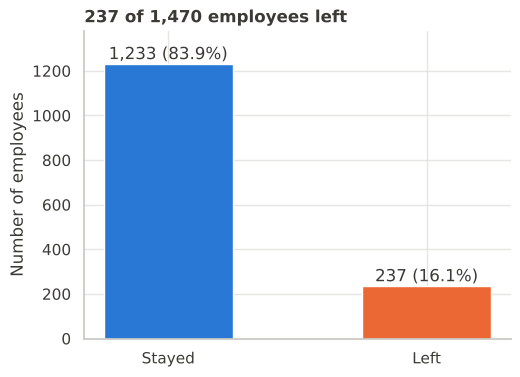

In [8]:
counts = df["Status"].value_counts().reindex(["Stayed", "Left"])

fig, ax = plt.subplots(figsize=(5.5, 4))
bars = ax.bar(counts.index, counts.values, color=[C_STAYED, C_LEFT], width=0.5)
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 20, f"{n:,} ({n / len(df):.1%})", ha="center")
ax.set_ylim(0, counts.max() * 1.12)
ax.set_ylabel("Number of employees")
ax.set_title(f"{counts['Left']} of {len(df):,} employees left")
sns.despine()
fig.savefig(CHARTS_DIR / "01_attrition_distribution.png")
plt.show()

**Finding.** About one employee in six (16.1%) left. The classes are imbalanced roughly 5 to 1.

**Why it matters.** A model that predicts "stayed" for everyone would be right 83.9% of the time while identifying nobody who leaves. Accuracy alone will therefore be a poor yardstick, and the baseline in Section 7 shows this directly.

### 5.2 Do leavers and stayers look different on numeric features?

Histograms below are scaled within each group (percent of that group), since there are far more stayers than leavers.

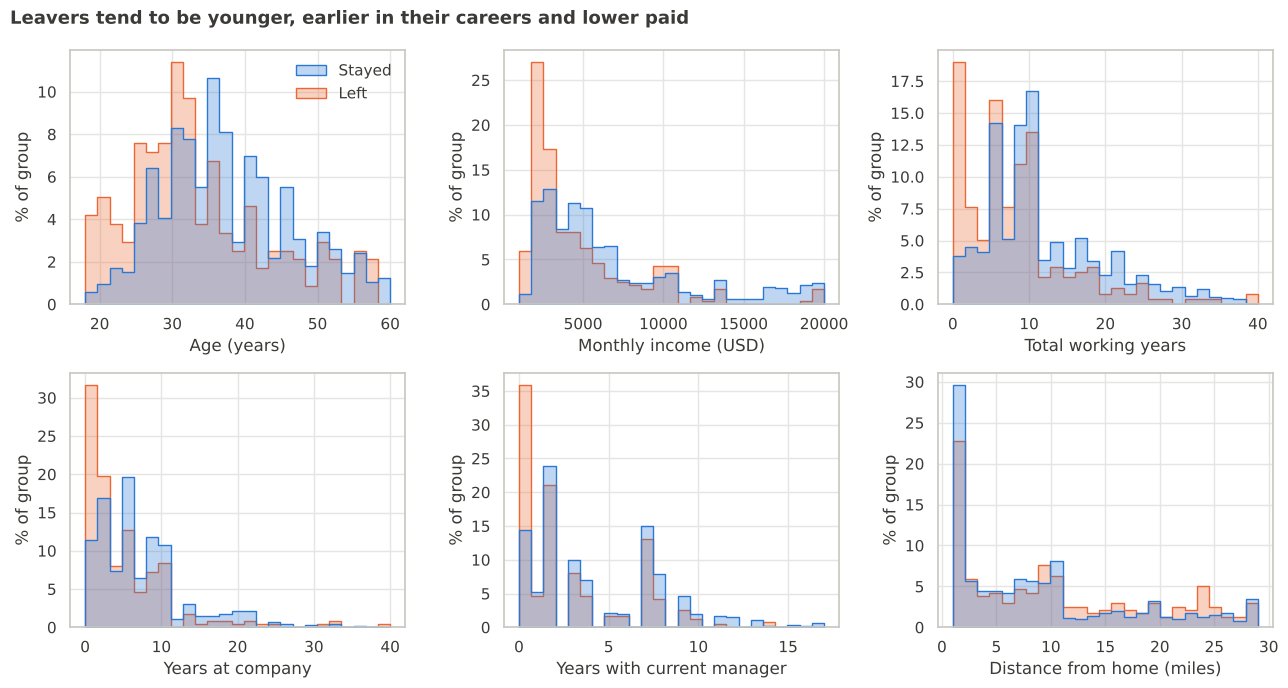

Status,Left,Stayed
Age,32.0,36.0
MonthlyIncome,3202.0,5204.0
TotalWorkingYears,7.0,10.0
YearsAtCompany,3.0,6.0
YearsWithCurrManager,2.0,3.0
DistanceFromHome,9.0,7.0


In [9]:
numeric_eda = {
    "Age": "Age (years)",
    "MonthlyIncome": "Monthly income (USD)",
    "TotalWorkingYears": "Total working years",
    "YearsAtCompany": "Years at company",
    "YearsWithCurrManager": "Years with current manager",
    "DistanceFromHome": "Distance from home (miles)",
}

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (col, label) in zip(axes.ravel(), numeric_eda.items()):
    sns.histplot(data=df, x=col, hue="Status", hue_order=["Stayed", "Left"],
                 palette={"Stayed": C_STAYED, "Left": C_LEFT}, stat="percent",
                 common_norm=False, element="step", bins=25, alpha=0.3, ax=ax)
    ax.set_xlabel(label)
    ax.set_ylabel("% of group")
    if ax is not axes[0, 0]:
        ax.get_legend().remove()
    else:
        sns.move_legend(ax, "upper right", title=None, frameon=False)
fig.suptitle("Leavers tend to be younger, earlier in their careers and lower paid", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "02_numerical_feature_distributions.png")
plt.show()

df.groupby("Status")[list(numeric_eda)].median().T.round(1)

**Finding.** The median leaver is 32 years old and earns about \$3,200 a month, compared with 36 years and about \$5,200 for the median stayer. Leavers also have fewer total working years (median 7 versus 10), less time at the company (3 years versus 6) and less time with their current manager (2 years versus 3); see the median table under the chart. The distributions overlap a lot, so none of these features separates the two groups cleanly. Distance from home shows a smaller shift (median 9 miles for leavers versus 7 for stayers).

**Why it matters, and alternative readings.** Age, income, working years and company tenure all move together, so these panels mostly show one underlying pattern ("early-career employees leave more often") viewed from several angles. The data cannot tell us which of those is doing the work. Income may matter in itself, or it may just reflect seniority.

### 5.3 Do some groups leave more than others?

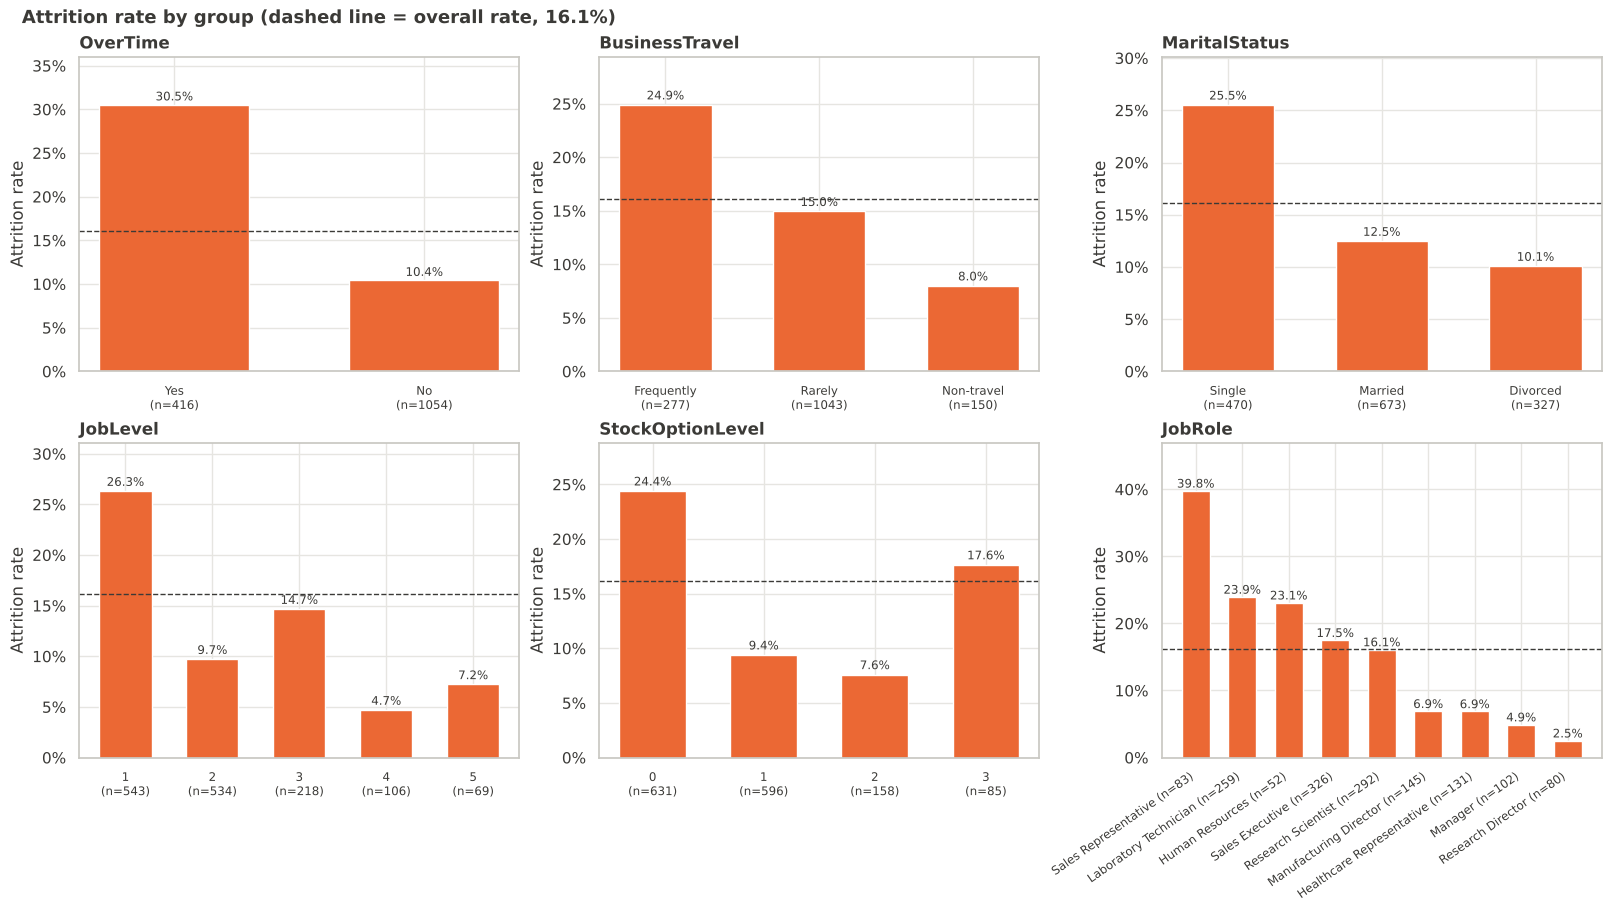

In [10]:
overall_rate = df["Left"].mean()
cat_eda = ["OverTime", "BusinessTravel", "MaritalStatus", "JobLevel", "StockOptionLevel", "JobRole"]
keep_numeric_order = {"JobLevel", "StockOptionLevel"}
short_names = {"Travel_Frequently": "Frequently", "Travel_Rarely": "Rarely", "Non-Travel": "Non-travel"}
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")

fig, axes = plt.subplots(2, 3, figsize=(16, 9), layout="constrained")
for ax, col in zip(axes.ravel(), cat_eda):
    t = df.groupby(col)["Left"].agg(rate="mean", n="size")
    t = t.sort_index() if col in keep_numeric_order else t.sort_values("rate", ascending=False)
    sep = " " if col == "JobRole" else "\n"   # rotated labels read better on one line
    names = [f"{short_names.get(name, name)}{sep}(n={n})" for name, n in zip(t.index, t["n"])]
    ax.bar(names, t["rate"], color=C_LEFT, width=0.6)
    ax.axhline(overall_rate, color=INK, linestyle="--", linewidth=1)
    for x_pos, rate in enumerate(t["rate"]):
        ax.text(x_pos, rate + 0.005, f"{rate:.1%}", ha="center", fontsize=8.5)
    ax.set_ylim(0, t["rate"].max() * 1.18)
    ax.set_ylabel("Attrition rate")
    ax.yaxis.set_major_formatter(pct)
    ax.tick_params(axis="x", labelsize=8.5)
    if col == "JobRole":
        plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
    ax.set_title(col)
fig.suptitle(f"Attrition rate by group (dashed line = overall rate, {overall_rate:.1%})",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.savefig(CHARTS_DIR / "03_categorical_attrition_comparison.png")
plt.show()

In [11]:
# Evidence for the "role vs level vs overtime" caveat discussed below
print("Employees by job level, for selected roles:")
print(pd.crosstab(df["JobRole"], df["JobLevel"]).loc[["Sales Representative", "Laboratory Technician", "Manager", "Research Director"]])
print()
print("Share working overtime, by job level:")
print(df.groupby("JobLevel")["OverTime"].apply(lambda s: (s == "Yes").mean()).round(2).to_string())

Employees by job level, for selected roles:
JobLevel                 1   2   3   4   5
JobRole                                   
Sales Representative    76   7   0   0   0
Laboratory Technician  200  56   3   0   0
Manager                  0   0  12  47  43
Research Director        0   0  28  26  26

Share working overtime, by job level:
JobLevel
1    0.29
2    0.27
3    0.29
4    0.31
5    0.26


**Finding.** The largest gaps are:

- **OverTime:** 30.5% of employees who work overtime left, versus 10.4% of those who do not (416 and 1,054 employees).
- **Job role:** Sales Representatives left at 39.8% (n=83), more than twice the overall rate, while Research Directors (2.5%, n=80) and Managers (4.9%, n=102) rarely left.
- **Job level and stock options:** level 1 employees left at 26.3% versus 9.7% at level 2 (and under 8% at level 5). Employees with no stock options left at 24.4% versus 9.4% with level 1 options. Stock option level 3 is a surprise (17.6%), but it has only 85 employees, so it could be noise.
- **Marital status and travel:** single employees left at 25.5% (married 12.5%, divorced 10.1%), and frequent travellers at 24.9% versus 8.0% for non-travellers.

**Why it matters, and caveats.** These are the groups where a closer look might pay off. They are associations, not causes. The table above shows that 76 of the 83 Sales Representatives (and 200 of 259 Laboratory Technicians) are level 1, so the role effect and the level effect are tangled together. Overtime looks like a separate effect: the share of employees working overtime is similar at every job level (26% to 31%). It might reflect overwork, or the type of work, and the data cannot say which. Small groups such as Human Resources (n=63 in the department split, 52 in the role split) give noisy rates. Also note the non-monotonic stock option pattern: a linear model that treats the level as a straight-line number cannot represent it.

### 5.4 Which numeric features correlate with leaving?

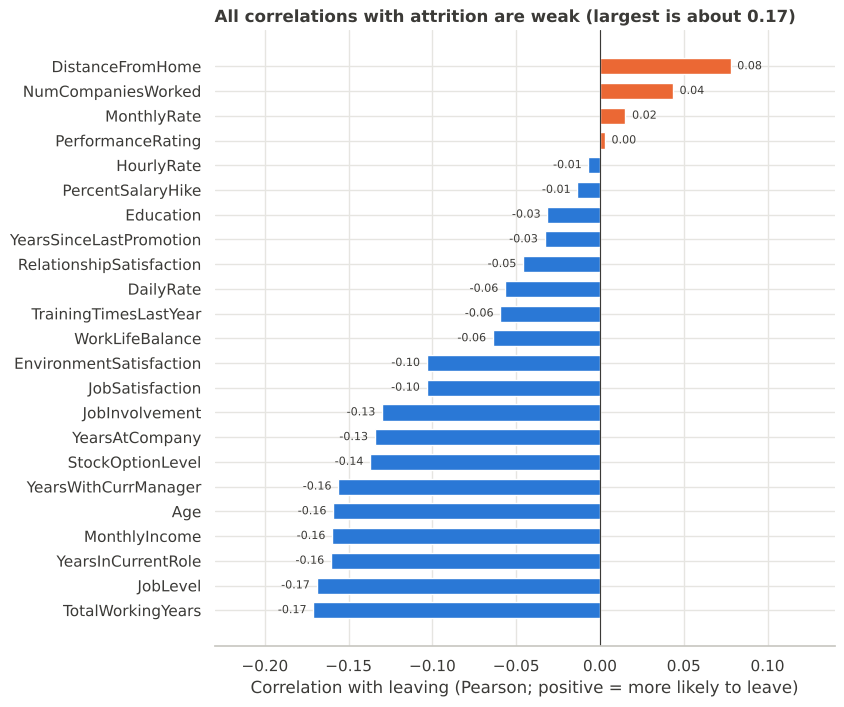

Feature pairs with |correlation| > 0.7:
JobLevel            MonthlyIncome           0.95
                    TotalWorkingYears       0.78
PercentSalaryHike   PerformanceRating       0.77
MonthlyIncome       TotalWorkingYears       0.77
YearsAtCompany      YearsWithCurrManager    0.77
                    YearsInCurrentRole      0.76
YearsInCurrentRole  YearsWithCurrManager    0.71

Pay-rate columns vs MonthlyIncome:
MonthlyIncome    1.00
DailyRate        0.01
HourlyRate      -0.02
MonthlyRate      0.03


In [12]:
numeric_cols_all = df.select_dtypes("number").columns.drop("Left")
corr_with_left = df[numeric_cols_all].corrwith(df["Left"]).sort_values()

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(corr_with_left.index, corr_with_left.values,
        color=[C_LEFT if v > 0 else C_STAYED for v in corr_with_left.values], height=0.65)
for y_pos, v in enumerate(corr_with_left.values):
    ax.text(v + (0.004 if v >= 0 else -0.004), y_pos, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, color=INK, linewidth=0.8)
ax.set_xlim(-0.23, 0.14)
ax.set_xlabel("Correlation with leaving (Pearson; positive = more likely to leave)")
ax.set_title("All correlations with attrition are weak (largest is about 0.17)")
sns.despine(left=True)
fig.savefig(CHARTS_DIR / "04_correlation_analysis.png")
plt.show()

# Features that are strongly correlated with each other
corr_abs = df[numeric_cols_all].corr().abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool)).stack()
print("Feature pairs with |correlation| > 0.7:")
print(upper[upper > 0.7].sort_values(ascending=False).round(2).to_string())
print()
print("Pay-rate columns vs MonthlyIncome:")
print(df[["MonthlyIncome", "DailyRate", "HourlyRate", "MonthlyRate"]].corr().round(2).loc["MonthlyIncome"].to_string())

**Finding.** Every numeric feature is only weakly correlated with leaving. The strongest are `TotalWorkingYears` and `JobLevel` (both about -0.17), followed by `YearsInCurrentRole`, `MonthlyIncome` and `Age` (about -0.16). `DistanceFromHome` is the strongest positive one (+0.08). Younger, lower-level, shorter-tenure employees leave a bit more, which matches Section 5.2.

**Why it matters.** No single numeric feature predicts attrition well on its own. The strongest signals in Section 5.3 (overtime, job role) are categorical and do not appear in this chart. Pearson correlation also only captures straight-line relationships, so it would miss patterns like the stock option one.

**Two things from the printed output affect modeling:**

- Several features are strongly correlated with each other: `JobLevel` and `MonthlyIncome` (0.95), `JobLevel` and `TotalWorkingYears` (0.78), `MonthlyIncome` and `TotalWorkingYears` (0.77), and the three tenure columns (0.71 to 0.77). A model cannot cleanly separate the effect of one from another, so individual coefficients in Section 10 should be read with care.
- `DailyRate`, `HourlyRate` and `MonthlyRate` have essentially zero correlation with `MonthlyIncome` (0.01, -0.02 and 0.03). In real payroll data I would expect pay rates and monthly income to be related, so this is another sign the dataset is synthetic. I kept these columns in the model because there is no strong reason to remove them, but I treat their importance with suspicion later.

## 6. Feature Preparation and Train/Test Split

**Target:** `Left` (1 = left, 0 = stayed).

**Inputs:** every column that remains after cleaning (30 features: numeric ratings and counts, plus categorical columns such as `JobRole`, `OverTime`, `MaritalStatus`). I did not hand-pick features, because the dataset is small and the models can handle all of them.

**Split first, preprocess second.** I hold out 20% of employees as a test set that is used only for the final evaluation. The split is **stratified**, so train and test keep the same 16.1% attrition rate. The preprocessing (scaling numeric columns, one-hot encoding categorical columns) is placed inside a scikit-learn `Pipeline`, so it is fitted on training data only. That avoids leaking information from the test set, including during cross-validation, where the pipeline is re-fitted within each fold.

In [13]:
X = df.drop(columns=["Attrition", "Status", "Left"])
y = df["Left"]

categorical_cols = X.select_dtypes(exclude="number").columns.tolist()
numeric_cols = X.select_dtypes(include="number").columns.tolist()
print(f"{len(numeric_cols)} numeric features, {len(categorical_cols)} categorical features")
print("Categorical:", categorical_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print()
print(f"Train: {len(X_train)} employees, {y_train.sum()} left ({y_train.mean():.1%})")
print(f"Test:  {len(X_test)} employees, {y_test.sum()} left ({y_test.mean():.1%})")

23 numeric features, 7 categorical features
Categorical: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Train: 1176 employees, 190 left (16.2%)
Test:  294 employees, 47 left (16.0%)


In [14]:
preprocessor = ColumnTransformer(
    [
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), categorical_cols),
    ],
    verbose_feature_names_out=False,
)

`StandardScaler` puts numeric features on a common scale, which logistic regression needs so that its coefficients are comparable. Random forests do not need it, but using the same preprocessing for both models keeps the comparison fair. `drop="if_binary"` encodes yes/no columns such as `OverTime` as a single 0/1 column instead of two mirror-image ones.

## 7. Establish a Baseline

A baseline gives a reference point. `DummyClassifier(strategy="most_frequent")` ignores all features and predicts the majority class ("stayed") for everyone.

In [15]:
def evaluate(name, fitted_model, X_eval, y_eval):
    """Return the main binary-classification metrics for one fitted model."""
    pred = fitted_model.predict(X_eval)
    proba = fitted_model.predict_proba(X_eval)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred),
        "F1": f1_score(y_eval, pred),
        "ROC-AUC": roc_auc_score(y_eval, proba),
    }


baseline = Pipeline([("prep", clone(preprocessor)),
                     ("model", DummyClassifier(strategy="most_frequent"))])
baseline.fit(X_train, y_train)
baseline_row = evaluate("Baseline (always 'stayed')", baseline, X_test, y_test)
pd.DataFrame([baseline_row]).set_index("Model").round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Baseline (always 'stayed'),0.84,0.0,0.0,0.0,0.5


**What this shows.** The baseline reaches **84.0% accuracy** on the test set (247 of 294 employees are stayers) while catching **none** of the 47 employees who left. Precision shows as 0 because it never predicts "left", recall is 0, and ROC-AUC is 0.5 (no ranking ability). Any real model has to beat this on recall, F1 and ROC-AUC, since beating it on accuracy would be nearly impossible without giving up recall.

## 8. Train and Compare Models

**Logistic Regression** fits a weighted sum of the features and turns it into a probability. It is simple, fast and easy to explain, because each coefficient says how a feature pushes the prediction up or down while the others are held fixed. It can only capture straight-line effects unless features are transformed.

**Random Forest** averages many decision trees, each trained on a random sample of the data. It can capture non-linear effects and interactions (for example "overtime *and* low job level") without being told about them, but it is harder to explain and can overfit small datasets.

**Handling the imbalance.** With only 16% leavers, a model trained naively tends to predict "stayed" too often. The lightest-touch fix is `class_weight="balanced"`, which makes mistakes on leavers count more during training. It does not change the data and needs no extra libraries. To check that it helps rather than assume it, I compare weighted and unweighted versions using **5-fold cross-validation on the training set only**. The test set stays untouched.

**No tuning.** The hyperparameters are fixed, sensible defaults (300 trees and `min_samples_leaf=3` for the forest, to stop individual trees from memorising a small dataset). There is no search, which keeps the comparison simple and avoids over-fitting to the validation folds.

**Selection rule (stated before looking at results).** I choose between the two models by their cross-validated **ROC-AUC** on the training data, because it does not depend on a particular decision threshold. Recall and F1 are reported alongside it, since catching leavers is the practical goal.

In [16]:
candidates = {
    "Logistic Regression (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
    "Logistic Regression (no weights)": LogisticRegression(max_iter=1000, random_state=SEED),
    "Random Forest (balanced)": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced",
                                                      random_state=SEED, n_jobs=-1),
    "Random Forest (no weights)": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                        random_state=SEED, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name, model in candidates.items():
    pipe = Pipeline([("prep", clone(preprocessor)), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=["roc_auc", "recall", "precision", "f1"])
    cv_rows.append({
        "Model": name,
        "CV ROC-AUC": scores["test_roc_auc"].mean(),
        "CV ROC-AUC std": scores["test_roc_auc"].std(),
        "CV Recall": scores["test_recall"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV F1": scores["test_f1"].mean(),
    })
cv_results = pd.DataFrame(cv_rows).set_index("Model")
cv_results.round(3)

,CV ROC-AUC,CV ROC-AUC std,CV Recall,CV Precision,CV F1
Model,,,,,
Logistic Regression (balanced),0.827,0.028,0.737,0.371,0.492
Logistic Regression (no weights),0.839,0.029,0.432,0.782,0.553
Random Forest (balanced),0.807,0.030,0.432,0.541,0.471
Random Forest (no weights),0.812,0.034,0.200,0.828,0.314


**Reading the cross-validation results (training data only)**

- **Model choice.** Under the rule I set, Logistic Regression (balanced) wins with a CV ROC-AUC of 0.827 versus 0.807 for the balanced Random Forest. The gap of about 0.02 is no bigger than the fold-to-fold spread (standard deviation about 0.03 for both), so the two models are close and Logistic Regression is not clearly better. It is simpler and easier to explain, which is a fair tie-breaker.
- **What class weighting does.** It does not improve the ranking of employees (AUC is about the same with and without it: 0.827 against 0.839 for logistic regression, 0.807 against 0.812 for the forest). It moves the model's operating point towards flagging more employees. Logistic regression recall rises from 0.43 to 0.74 while precision falls from 0.78 to 0.37; the forest goes from recall 0.20 and precision 0.83 to recall 0.43 and precision 0.54.
- **Judgement call.** Weighting is a trade-off rather than a free improvement, and for logistic regression the F1 score is actually lower with it (0.49 versus 0.55). I keep `class_weight="balanced"` for both final models because, for this problem, I care more about not missing leavers than about avoiding false alarms. If false alarms were costly, the unweighted models would be a defensible choice. This decision is separate from the AUC rule above, which only decides between the two *types* of model.

In [17]:
# Final models: fitted on the full training set, then evaluated once on the test set
final_models = {
    "Logistic Regression": Pipeline([("prep", clone(preprocessor)),
                                     ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))]),
    "Random Forest": Pipeline([("prep", clone(preprocessor)),
                               ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced",
                                                                random_state=SEED, n_jobs=-1))]),
}
for pipe in final_models.values():
    pipe.fit(X_train, y_train)

## 9. Evaluate Model Performance

What each metric means here (positive class = *employee left*):

- **Accuracy:** share of all employees classified correctly. Misleading when 84% of employees stay.
- **Precision:** of the employees the model flags as likely to leave, the share who really left. Low precision means many false alarms (stayers flagged), which costs HR time and risks awkward conversations.
- **Recall:** of the employees who really left, the share the model flagged. Low recall means leavers slip through unnoticed. This is the metric I watch most closely.
- **F1:** a single number balancing precision and recall.
- **ROC-AUC:** how well the predicted probabilities rank leavers above stayers, regardless of threshold. 0.5 is a coin flip and 1.0 is perfect.

Precision and recall pull against each other. Flagging more employees raises recall but lowers precision.

In [18]:
results = pd.DataFrame(
    [baseline_row] + [evaluate(name, pipe, X_test, y_test) for name, pipe in final_models.items()]
).set_index("Model")
results.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Baseline (always 'stayed'),0.840,0.000,0.000,0.000,0.500
Logistic Regression,0.752,0.349,0.638,0.451,0.802
Random Forest,0.823,0.444,0.426,0.435,0.775


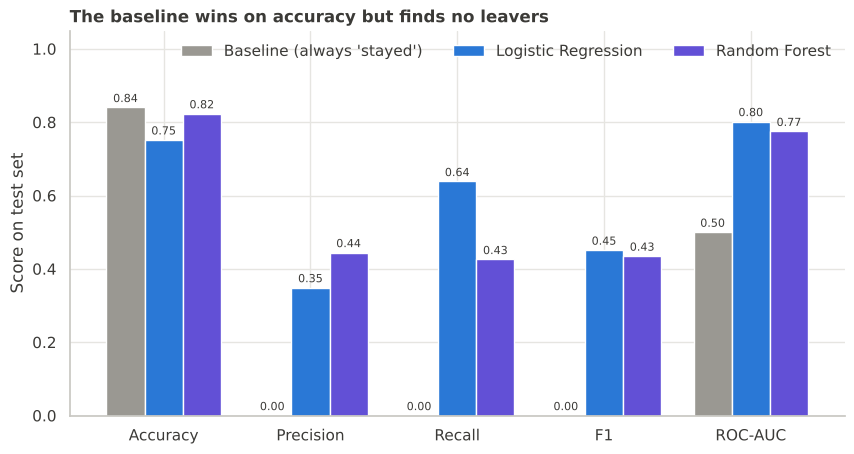

In [19]:
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
fig, ax = plt.subplots(figsize=(10, 5))
results[metrics].T.plot(kind="bar", ax=ax, color=[C_BASELINE, C_LR, C_RF], width=0.78, rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score on test set")
ax.set_title("The baseline wins on accuracy but finds no leavers")
ax.legend(title=None, frameon=False, loc="upper right", ncol=3)
sns.despine()
fig.savefig(CHARTS_DIR / "05_model_performance_comparison.png")
plt.show()

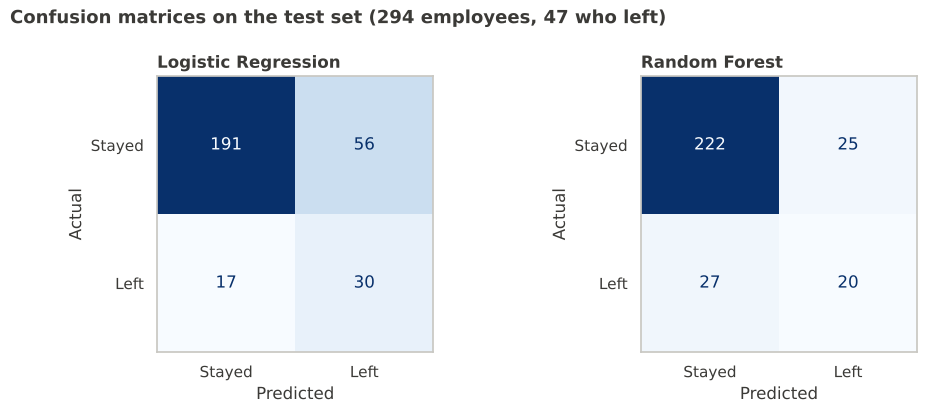

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (name, pipe) in zip(axes, final_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        pipe, X_test, y_test, display_labels=["Stayed", "Left"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.grid(False)
fig.suptitle("Confusion matrices on the test set (294 employees, 47 who left)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "06_confusion_matrix.png")
plt.show()

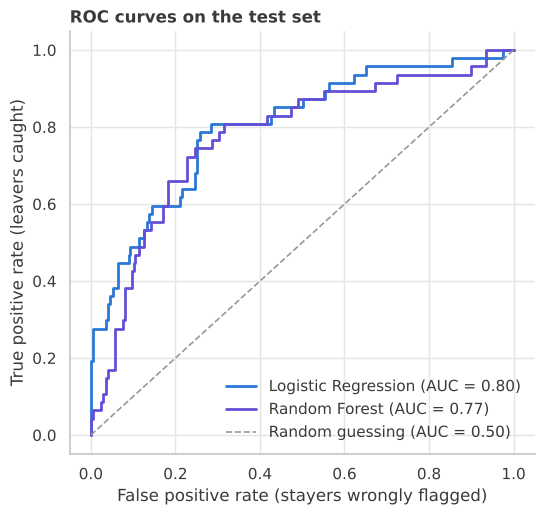

In [21]:
fig, ax = plt.subplots(figsize=(6, 5.5))
for (name, pipe), color in zip(final_models.items(), [C_LR, C_RF]):
    fpr, tpr, _ = roc_curve(y_test, pipe.predict_proba(X_test)[:, 1])
    auc = results.loc[name, "ROC-AUC"]
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{name} (AUC = {auc:.2f})")
ax.plot([0, 1], [0, 1], color=C_BASELINE, linestyle="--", linewidth=1.2, label="Random guessing (AUC = 0.50)")
ax.set_xlabel("False positive rate (stayers wrongly flagged)")
ax.set_ylabel("True positive rate (leavers caught)")
ax.set_title("ROC curves on the test set")
ax.legend(frameon=False, loc="lower right")
sns.despine()
fig.savefig(CHARTS_DIR / "07_roc_curve.png")
plt.show()

### How much should we trust these numbers?

The test set has only 47 leavers, so a single recall or AUC value is noisy. The cell below resamples the test set with replacement 1,000 times to get a rough 95% interval for each model's recall and ROC-AUC. This quantifies the noise but does not remove it.

In [22]:
rng = np.random.default_rng(SEED)
y_true = y_test.to_numpy()
test_preds = {name: (pipe.predict(X_test), pipe.predict_proba(X_test)[:, 1]) for name, pipe in final_models.items()}

rows = []
for name, (pred, proba) in test_preds.items():
    recalls, aucs = [], []
    for _ in range(1000):
        idx = rng.integers(0, len(y_true), len(y_true))
        recalls.append(recall_score(y_true[idx], pred[idx]))
        aucs.append(roc_auc_score(y_true[idx], proba[idx]))
    rows.append({
        "Model": name,
        "Recall 95% interval": f"{np.percentile(recalls, 2.5):.2f} to {np.percentile(recalls, 97.5):.2f}",
        "ROC-AUC 95% interval": f"{np.percentile(aucs, 2.5):.2f} to {np.percentile(aucs, 97.5):.2f}",
    })
pd.DataFrame(rows).set_index("Model")

,Recall 95% interval,ROC-AUC 95% interval
Model,,
Logistic Regression,0.50 to 0.78,0.73 to 0.87
Random Forest,0.28 to 0.57,0.69 to 0.84


**Results on the test set**

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Baseline (always "stayed") | 0.840 | 0.000 | 0.000 | 0.000 | 0.500 |
| Logistic Regression | 0.752 | 0.349 | 0.638 | 0.451 | 0.802 |
| Random Forest | 0.823 | 0.444 | 0.426 | 0.435 | 0.775 |

**In practice, from the confusion matrices:**

- **Logistic Regression** flags 86 of 294 employees (29%). 30 of them did leave and 56 did not. It misses 17 of the 47 leavers.
- **Random Forest** flags 45 employees. 20 of them left and 25 did not. It misses 27 of the 47 leavers.

**How to read this.**

- Logistic Regression has *lower* accuracy than the baseline (0.752 versus 0.840) but is the only option that finds a majority of leavers (recall 0.64). That is the trade the weighting was meant to make: it accepts many false alarms to catch more leavers.
- Precision of 0.35 means about one flagged employee in three is a real leaver. Since one employee in six leaves overall (16%), that is roughly twice as good as flagging people at random, but still means about two in three flagged employees would have stayed.
- The Random Forest is more conservative: higher precision (0.44) and accuracy, lower recall (0.43). Its F1 is about the same as the logistic regression's (0.435 versus 0.451).
- Under the criteria I chose (cross-validated ROC-AUC, with recall as the practical priority), Logistic Regression is the better model, and it also comes out ahead on recall and ROC-AUC on the test set.

**But the evidence is not strong.** The bootstrap intervals are wide: recall is 0.50 to 0.78 for logistic regression and 0.28 to 0.57 for the forest, and the ROC-AUC intervals (0.73 to 0.87 and 0.69 to 0.84) overlap almost completely. The recall advantage of logistic regression is suggestive but not conclusive, and the AUC difference cannot be distinguished from noise. A ROC-AUC around 0.80 is decent for this kind of problem, but it is not accurate enough to make decisions about individual people. During development, a small change in how the binary columns were encoded moved the Random Forest's test recall by several points, which is another reminder of how unstable results are with only 47 leavers in the test set.

## 10. Model Interpretation

Two views of which features the models rely on:

- **Logistic Regression coefficients.** Numeric features were standardised, so a coefficient is the change in the log-odds of leaving for a one-standard-deviation increase in that feature, with the other features held fixed. Positive means "pushes toward leaving". For one-hot columns, it is the effect of being in that category.
- **Random Forest importance.** How much each feature reduces impurity across the forest's splits. It shows how *useful* a feature was to the forest, not which direction it pushes. It also tends to favour numeric features with many distinct values.

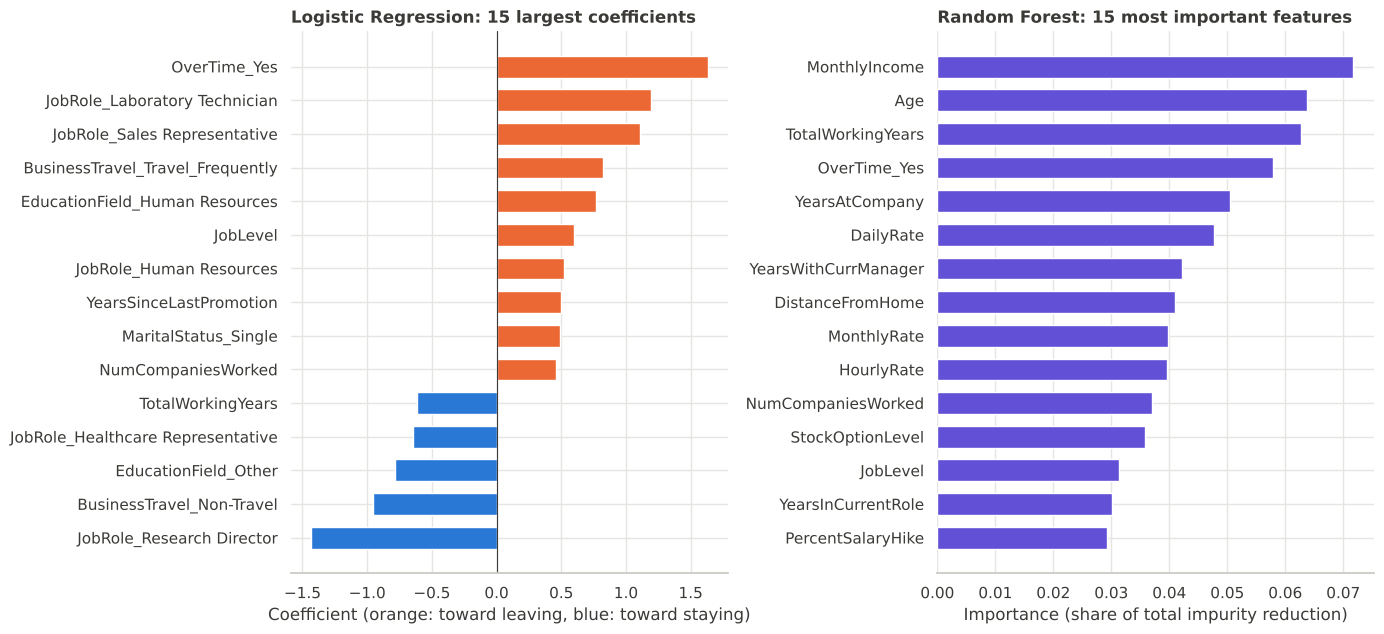

Top 5 by Random Forest importance: MonthlyIncome, Age, TotalWorkingYears, OverTime_Yes, YearsAtCompany
Top 5 by |LR coefficient|:         OverTime_Yes, JobRole_Research Director, JobRole_Laboratory Technician, JobRole_Sales Representative, BusinessTravel_Non-Travel


In [23]:
feature_names = final_models["Logistic Regression"].named_steps["prep"].get_feature_names_out()

lr_coefs = pd.Series(final_models["Logistic Regression"].named_steps["model"].coef_[0], index=feature_names)
top_lr = lr_coefs.reindex(lr_coefs.abs().sort_values(ascending=False).index).head(15).sort_values()

rf_importance = pd.Series(final_models["Random Forest"].named_steps["model"].feature_importances_, index=feature_names)
top_rf = rf_importance.sort_values(ascending=False).head(15).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
axes[0].barh(top_lr.index, top_lr.values, color=[C_LEFT if v > 0 else C_STAYED for v in top_lr.values], height=0.65)
axes[0].axvline(0, color=INK, linewidth=0.8)
axes[0].set_xlabel("Coefficient (orange: toward leaving, blue: toward staying)")
axes[0].set_title("Logistic Regression: 15 largest coefficients")

axes[1].barh(top_rf.index, top_rf.values, color=C_RF, height=0.65)
axes[1].set_xlabel("Importance (share of total impurity reduction)")
axes[1].set_title("Random Forest: 15 most important features")

sns.despine(left=True)
fig.tight_layout()
fig.savefig(CHARTS_DIR / "08_feature_importance.png")
plt.show()

print("Top 5 by Random Forest importance:", ", ".join(top_rf.sort_values(ascending=False).head(5).index))
print("Top 5 by |LR coefficient|:        ", ", ".join(top_lr.abs().sort_values(ascending=False).head(5).index))

**What the models rely on**

*Logistic Regression.* The largest coefficient by far is `OverTime_Yes` (+1.63), which corresponds to roughly five times the odds of leaving for employees working overtime, with the other features held fixed. Job role is next: Research Directors (-1.44) are much less likely to leave, while Laboratory Technicians (+1.20) and Sales Representatives (+1.11) are more likely. Business travel matters too (frequent travel +0.82, no travel -0.96), as do being single (+0.49), years since the last promotion (+0.50) and the number of previous employers (+0.46). `TotalWorkingYears` has a negative coefficient (-0.62 per standard deviation), meaning more experienced employees are less likely to leave.

*Random Forest.* The most important features are `MonthlyIncome`, `Age`, `TotalWorkingYears`, `OverTime_Yes` and `YearsAtCompany`. The importance is spread thinly: the top three features add up to only about 20% of the total and the top ten to about 52%.

**Where the two views agree and differ.** Both put `OverTime_Yes` near the top. Beyond that they emphasise different things: the forest favours age, income and tenure, while the logistic regression favours job role, travel and overtime. This is not necessarily a contradiction. Age, income, job level and working years are strongly correlated (Section 5.4), so the logistic regression splits their combined effect among them and each ends up with a small coefficient, while the forest's importance score is also known to favour numeric features with many distinct values.

**Cautions.**

- `JobLevel` has a *positive* coefficient (+0.60, towards leaving) even though level 1 employees leave the most in the raw data. This is most likely a side effect of its 0.95 correlation with `MonthlyIncome` and its 0.78 correlation with `TotalWorkingYears`. It is a good example of why individual coefficients should not be over-read when features overlap.
- `DailyRate`, `MonthlyRate` and `HourlyRate` all appear in the forest's top ten even though they are unrelated to monthly income and look like noise. Impurity-based importance can reward continuous features simply because they offer many places to split. I did not check this with permutation importance, so I treat these three as probably inflated.

**For a non-technical reader.** In this dataset, the employees the models see as higher risk are those who work overtime, travel frequently, are in junior roles such as laboratory technician or sales representative, are early in their careers or lower paid, and are single. Research directors and managers are rarely flagged. These are the patterns the models use to predict, not explanations of why anyone leaves. Feature importance and coefficients describe associations in historical data. They do not show that overtime *causes* people to leave, and they say nothing about any individual's personal reasons.

## 11. Final Findings and Recommendations

**Question 1: what is the problem?** In this dataset 237 of 1,470 employees (16.1%) left. Attrition is costly because replacing people takes money and time, and the data lets us look at which groups lose people more often.

**Question 2: what patterns are associated with attrition?**

- **Overtime** is the clearest single pattern: 30.5% of overtime workers left versus 10.4% of the others. Overtime is spread fairly evenly across job levels (26% to 31%), so it is not just a seniority effect.
- **Role and level:** Sales Representatives (39.8%) and Laboratory Technicians (23.9%) left most often; Research Directors (2.5%) and Managers (4.9%) rarely did. Level 1 employees left at 26.3% versus 4.7% to 14.7% at levels 2 to 5.
- **Early career and lower pay:** the median leaver is 32 years old with 3 years at the company and a monthly income of about USD 3,200, compared with 36 years, 6 years and about USD 5,200 for the median stayer.
- **Frequent business travel** (24.9% versus 8.0% for non-travellers), **single status** (25.5% versus 10.1% to 12.5%) and having **no stock options** (24.4% versus 7.6% to 9.4% at levels 1 and 2) also go with higher attrition.
- No numeric feature has a correlation with attrition above 0.17 in size, and many of these features overlap, so the data cannot tell us which of them matters most.

**Question 3: can we predict attrition?** Partly. Logistic Regression was the better model under the criteria chosen in advance (cross-validated ROC-AUC 0.827 versus 0.807 for the forest, with recall as the practical priority). On the test set it reaches ROC-AUC 0.80, recall 0.64 and precision 0.35, against a baseline that finds no leavers.

- *Strengths:* it catches about two of every three leavers, it is simple and explainable, and it clearly beats the baseline on the measures that matter.
- *Weaknesses:* about two in three flagged employees would have stayed, 17 of the 47 leavers in the test set were still missed, and the test set is small enough that the comparison with the Random Forest is not conclusive.

**Most informative features:** overtime, job role, business travel, and age, income and tenure (Section 10).

**Recommendations (to investigate, not conclusions).** These follow from associations in a fictional dataset, so they are starting points for questions an HR team would ask of its own data:

1. Look at overtime workloads, especially in the roles with the highest attrition. Check whether overtime is voluntary, how it is compensated and whether it is concentrated on particular teams.
2. Review the junior sales and laboratory roles, where attrition is highest: pay progression, promotion paths and workload.
3. Look at early-career retention, for example onboarding and mentoring, since leavers have a median of 3 years at the company.
4. Look at how much frequent travel is required and whether it is shared fairly.
5. If a model like this is ever used, use it to prioritise group-level reviews rather than to make decisions about individuals, and validate it on the organisation's own data first.

**Limitations and possible sources of bias**

- The data is fictional and a single snapshot. It has no dates, no reasons for leaving, and no distinction between voluntary and involuntary exits, so the findings may not carry over to a real company.
- The dataset does not document when the survey-type columns (satisfaction, work-life balance) were recorded relative to the departure. If some were recorded after an employee decided to leave, a real model would not have them in advance.
- With 237 leavers (47 in the test set) and a single train/test split, all performance numbers are noisy.
- The model uses `Age`, `Gender` and `MaritalStatus`, which could lead to unfair treatment of individuals if the model were used for decisions. I did not run a fairness audit.
- The strongly correlated features make individual coefficients and importances hard to interpret, and some columns (`DailyRate`, `MonthlyRate`, `HourlyRate`) look like noise.

**Possible improvements:** repeated cross-validation for more stable estimates, choosing the decision threshold from the relative cost of missed leavers and false alarms, permutation importance, trying gradient boosting, grouping rare categories, removing or combining overlapping features, and testing on a different dataset (ideally one with tenure and timing information, which would allow survival analysis).

## 12. Reproducibility and Final Summary

In [24]:
print("Python packages used:")
print("  pandas       ", pd.__version__)
print("  numpy        ", np.__version__)
print("  scikit-learn ", sklearn.__version__)
print("  matplotlib   ", plt.matplotlib.__version__)
print("  seaborn      ", sns.__version__)
print()
print("Random seed:", SEED)
print("Charts saved to", CHARTS_DIR.relative_to(ROOT))
for path in sorted(CHARTS_DIR.glob("*.png")):
    print("  ", path.name)

Python packages used:
  pandas        3.0.5
  numpy         2.5.3
  scikit-learn  1.9.1
  matplotlib    3.11.2
  seaborn       0.13.2

Random seed: 42
Charts saved to charts
   01_attrition_distribution.png
   02_numerical_feature_distributions.png
   03_categorical_attrition_comparison.png
   04_correlation_analysis.png
   05_model_performance_comparison.png
   06_confusion_matrix.png
   07_roc_curve.png
   08_feature_importance.png


**Summary.** This notebook loaded the IBM HR attrition dataset (1,470 employees, 16.1% leavers), removed four uninformative columns, explored which groups leave more often, and compared a majority-class baseline with a Logistic Regression and a Random Forest inside leakage-safe pipelines. The best model under the pre-stated criteria was Logistic Regression (test ROC-AUC 0.80, recall 0.64, precision 0.35). It is a useful screening signal at best, with wide uncertainty, and it shows associations rather than causes.

**Reproducing it.** Install the packages in `requirements.txt` and run the notebook from top to bottom. It reads `data/raw/employee_attrition.csv`, uses a fixed random seed (42), and rewrites the charts in `charts/`. The package versions used for the results above are printed in the previous cell.